**Nombre:** Kevin Abraham Fernandez Sanchez

**Matrícula:** 25041246

**Materia:** Probabilidad y Estadística

**Caso 25 Extra: Distribución Exponencial**

**Herramienta de cálculo:** Python (Google Colab)


**Rubén Pizarro Gurrola**

**Abril 2025**

# Objetivo

Calcular probabilidades, visualizar densidades y determinar el valor esperado y
variabilidad de los datos de distribuciones exponenciales.

# Marco teórico

La distribución exponencial y la distribución de Poisson están estrechamente relacionadas porque ambas modelan procesos en los que los eventos ocurren de manera aleatoria en el tiempo o en el espacio.


La distribución exponencial es una distribución de probabilidad continua que se usa comúnmente para modelar el tiempo entre eventos en un proceso de Poisson, es decir, un proceso donde los eventos ocurren de manera aleatoria e independiente a una tasa constante.

## Función de Densidad

La función de densidad de probabilidad (PDF) de la distribución exponencial es:

$$
f(x) = \lambda e^{-\lambda x}, \quad x \geq 0
$$

donde $(\lambda > 0)$ es el parámetro de la distribución.

* λ es la tasa de ocurrencia de eventos (también llamada parámetro de escala o inverso de la media).

* 𝑒 es la base del logaritmo natural (≈2.718).

𝑥 representa el tiempo transcurrido hasta el siguiente evento.

## Función acumulada o de probabilidad

$$
F(x) = P(X \leq x) = 1 - e^{-\lambda x}, \quad x \geq 0
$$

## Valor esperado E(x)

el valor promedio esperado de
𝑋 es el inverso de 𝜆.

$$
E[X] = \frac{1}{\lambda}
$$

## Varianza

La varianza mide la dispersión de los valores respecto a la media.

$$
\sigma^2 = \frac{1}{\lambda^2}
$$


## Desviación estándar

$$
\sigma = \sqrt{\frac{1}{\lambda^2}}
$$


¿Para qué se utiliza?

Se usa principalmente para modelar el tiempo de espera hasta que ocurre un evento en procesos donde los eventos ocurren de manera aleatoria y con una tasa constante. Ejemplos:

* 1. Vida útil de productos. Se usa en análisis de confiabilidad y mantenimiento predictivo.

* 2. Sistemas de colas y tiempos de espera. Tiempos entre llegadas de clientes en un sistema de servicio (ej. llamadas en un call center, llegadas a un banco o hospital).

* 3. Procesos de Poisson y ocurrencia de eventos aleatorios.
Tiempo entre sismos en una región.
Tiempo entre fallas en un sistema informático. Tiempo entre llegadas de autos en un peaje.

* 4. Modelado de tiempos de reacción y supervivencia. En biomedicina, se usa en análisis de supervivencia para modelar el tiempo hasta la muerte de un paciente

* 5. Economía y Finanzas
Se usa para modelar el tiempo hasta que ocurre un cambio en una variable económica o financiera.



# Desarrollo


## Cargar librerías


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats

## Cargar funciones

In [2]:
# Graficar el histograma y la función de densidad teórica
def f_visualizar_exponencial(datos, lambda_param):

  x = np.linspace(0, np.max(datos), 1000)
  pdf = lambda_param * np.exp(-lambda_param * x)  # Función de densidad teórica

  plt.figure(figsize=(8,5))
  plt.hist(datos, bins=50, density=True, alpha=0.6, color='blue', label='Histograma')
  plt.plot(x, pdf, 'b-', label='Densidad teórica')

  # Mostrar estadísticas en el gráfico
  plt.axvline(media, color='red', linestyle='dashed', label=f'Media: {media:.2f}')
  plt.axvline(media + desviacion_estandar, color='green', linestyle='dashed', label=f'+1σ: {media + desviacion_estandar:.2f}')
  plt.axvline(media - desviacion_estandar, color='green', linestyle='dashed')

  plt.title('Distribución Exponencial ($\lambda$ ='+str(lambda_param)+')')
  plt.xlabel('Valor de X')
  plt.ylabel('Densidad de probabilidad')
  plt.legend()
  plt.grid()
  plt.show()

  # Imprimir estadísticas
  print(f"Media: {media:.4f} (Esperado: {1/lambda_param:.4f})")
  print(f"Varianza: {varianza:.4f} (Esperado: {(1/lambda_param)**2:.4f})")
  print(f"Desviación estándar: {desviacion_estandar:.4f} (Esperado: {1/lambda_param:.4f})")

def f_prob_visual_exponencial(lambd, expresion):
    """
    Calcula y representa visualmente el área sombreada bajo la curva de una distribución exponencial.

    Args:
        lambd: Parámetro lambda de la distribución exponencial.
        expresion: Una cadena que representa la expresión de probabilidad, por ejemplo "P(X<=2)".
    """

    try:
        # Extraer el límite de la expresión
        limite = float(expresion.split("<=")[1].split(")")[0]) if "<=" in expresion else float(expresion.split(">=")[1].split(")")[0])
    except (ValueError, IndexError):
        print("Error: La expresión de probabilidad no es válida.")
        return

    x = np.linspace(0, limite * 2 , 1000) # Se extiende el rango para una mejor visualización
    pdf = lambd * np.exp(-lambd * x)

    # Calcular el área sombreada
    if "<=" in expresion:
        area = stats.expon.cdf(limite, scale=1/lambd)
    elif ">=" in expresion:
        area = 1-stats.expon.cdf(limite, scale=1/lambd) #Probabilidad acumulada
    else:
        print("Error: Operador no soportado")
        return


    plt.figure(figsize=(8, 5))
    plt.plot(x, pdf, 'b-', label='Función de Densidad')

    # Sombrear el área
    if "<=" in expresion:
        plt.fill_between(x, pdf, where=(x <= limite), color='skyblue', alpha=0.6, label=f'Área: {area:.4f}')
    elif ">=" in expresion:
      plt.fill_between(x, pdf, where=(x >= limite), color='skyblue', alpha=0.6, label=f'Área: {area:.4f}')

    plt.title(f'Distribución Exponencial (λ = {lambd}), {expresion}')
    plt.xlabel('X')
    plt.ylabel('f(x)')
    plt.legend()
    plt.grid(True)
    plt.show()

    print(f"El valor del área sombreada para {expresion} es: {area:.4f}")


<>:16: SyntaxWarning: invalid escape sequence '\l'
<>:16: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_178/3429833806.py:16: SyntaxWarning: invalid escape sequence '\l'
  plt.title('Distribución Exponencial ($\lambda$ ='+str(lambda_param)+')')


## Generar valores aleatorios

Se generan valores aleatorios de una distribución exponencial.

Se define un valor de taza de ocurrencia de cualqueir evento, luego se generan a partir de ese valor números aleatorios basados en distribución exponencial y posteriormente, se calculan valor esperado, varianza  y desviación estándar.



In [3]:
# Parámetro lambda de la distribución exponencial
lambda_param = 5  # Tasa de ocurrencia
np.random.seed(2025)  # para que salgan siempre los mismos números

# Generar 10,000 valores de una distribución exponencial
datos = np.random.exponential(scale=1/lambda_param, size=10000)

# Calcular estadísticas
media = np.mean(datos)
varianza = np.var(datos)
desviacion_estandar = np.std(datos)

print ("Los datos son:")
print(datos)


print(f"Media: {media}")
print(f"Varianza: {varianza}")
print(f"Desviación Estándar: {desviacion_estandar}")

Los datos son:
[0.02911806 0.43758664 0.53943879 ... 0.06074603 0.11044477 0.64819604]
Media: 0.20049806503658057
Varianza: 0.039714305402384076
Desviación Estándar: 0.19928448359665155


## Visualización


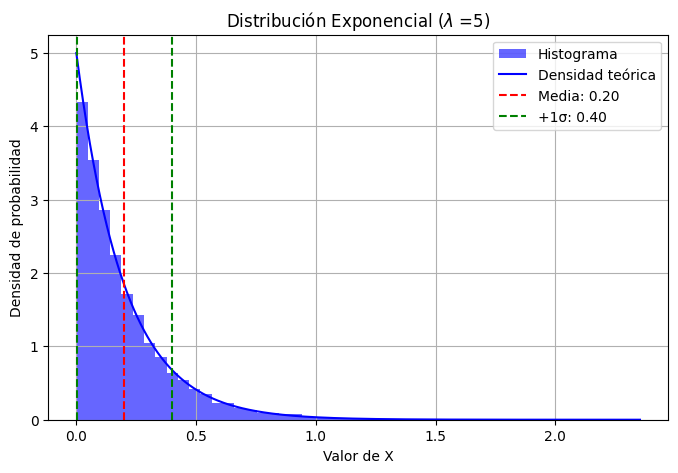

Media: 0.2005 (Esperado: 0.2000)
Varianza: 0.0397 (Esperado: 0.0400)
Desviación estándar: 0.1993 (Esperado: 0.2000)


In [4]:
f_visualizar_exponencial(datos, lambda_param)

## Ejercicio

El tiempo (en minutos) entre la llegada de clientes a un cajero automático sigue una distribución exponencial con una tasa de
𝜆 = 3 llegadas por minuto.

* ¿Cuál es la probabilidad de que el siguiente cliente llegue en menos de *30* segundos?; *30* segundos es *0.5* minutos.



P(X ≤ 0.5) = 0.7769 ≈ 77.6870%


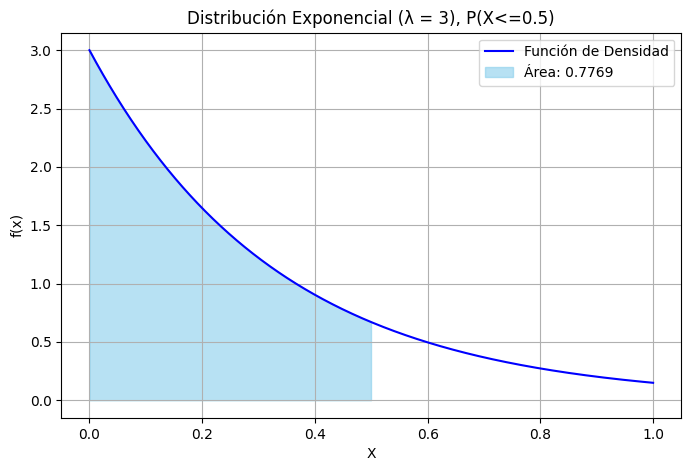

El valor del área sombreada para P(X<=0.5) es: 0.7769


In [5]:
# Parámetro lambda

lambda_param = 3  # llegadas por minuto

# Pregunta 1: P(X ≤ 30)
x = 0.5 # 30 SEGUNDOS ES MEDIO MINUTO
prob1 = 1 - np.exp(-lambda_param * x)

# Mostrar resultados
print(f"P(X ≤ 0.5) = {prob1:.4f} ≈ {prob1*100:.4f}%")

# Llamar la función
f_prob_visual_exponencial(lambda_param, expresion="P(X<=0.5)") # Probabilidad de que x sea menor o igual que 0.5


* ¿Cuál es la probabilidad de que el siguiente cliente tarde más de 1 minuto en llegar?

P(X >= 1) = 0.0498 ≈ 4.9787%


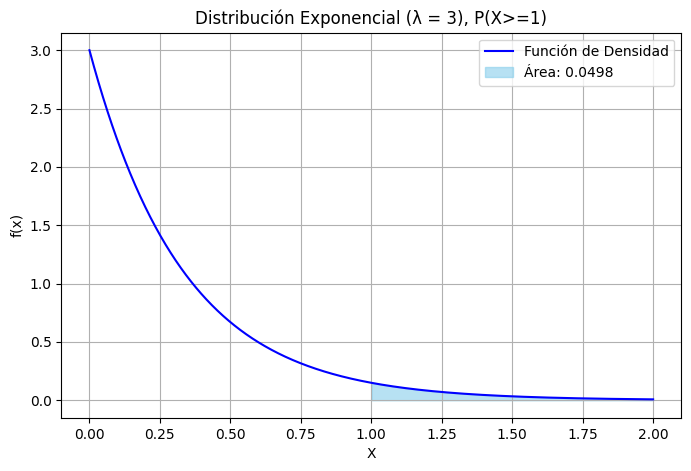

El valor del área sombreada para P(X>=1) es: 0.0498


In [6]:
# Pregunta 2: P(X > 1)
x = 1
prob2 = np.exp(-lambda_param * x)

# Mostrar resultados
print(f"P(X >= 1) = {prob2:.4f} ≈ {prob2*100:.4f}%")

# Llamar la función
f_prob_visual_exponencial(lambda_param, expresion="P(X>=1)") # Probabilidad de que x sea mayor o igual que 1



## Valor esperado y Variabilidad



In [7]:
# Parámetro lambda de la distribución exponencial
lambda_param = 3  # Tasa de ocurrencia
np.random.seed(2025)  # para que salgan siempre los mismos números

# Generar 10,000 valores de una distribución exponencial
datos = np.random.exponential(scale=1/lambda_param, size=10000)

# Calcular estadísticas
media = np.mean(datos)
varianza = np.var(datos)
desviacion_estandar = np.std(datos)

print ("Los datos son:")
print(datos)


print(f"Media: {media}")
print(f"Varianza: {varianza}")
print(f"Desviación Estándar: {desviacion_estandar}")

Los datos son:
[0.04853009 0.72931107 0.89906465 ... 0.10124338 0.18407462 1.08032674]
Media: 0.33416344172763424
Varianza: 0.1103175150066224
Desviación Estándar: 0.3321408059944192


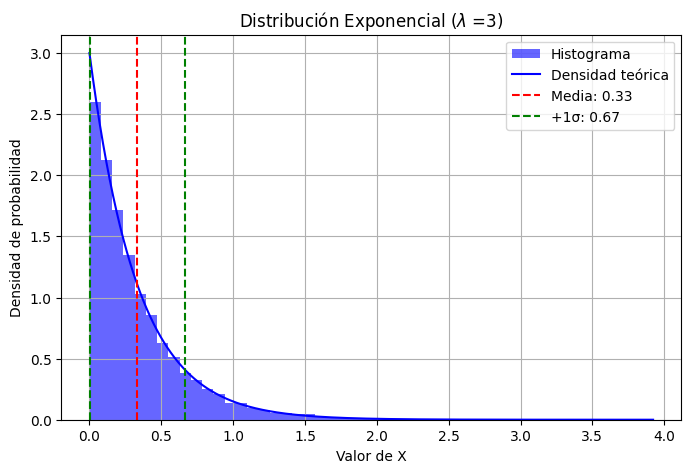

Media: 0.3342 (Esperado: 0.3333)
Varianza: 0.1103 (Esperado: 0.1111)
Desviación estándar: 0.3321 (Esperado: 0.3333)


In [8]:
f_visualizar_exponencial(datos, lambda_param)

## Ejercicio Cafetería

Una cafetería universitaria ha observado que, durante cierto horario, transcurren en promedio *15* minutos entre la llegada de un cliente y el siguiente. Se supone que el tiempo entre llegadas puede modelarse mediante una distribución Exponencial.

$$
X=\text{tiempo, en minutos, hasta la llegada del siguiente cliente}
$$

Como el tiempo promedio es:
$$
E(X)=15
$$
entonces:
$$
\lambda=\frac{1}{15}=0.06667
$$

La función de densidad para este ejercicio es:

$$
f(x) = \lambda e^{-\lambda x}, \quad x \geq 0
$$

$$
f(x) = \frac{1}{15} e^{-\frac{x}{15}}, \quad x \geq 0
$$

### ¿Cuál es la probabilidad de que el siguiente cliente llegue antes de 10 minutos?



P(X ≤ 10) = 0.4866 ≈ 48.6583%


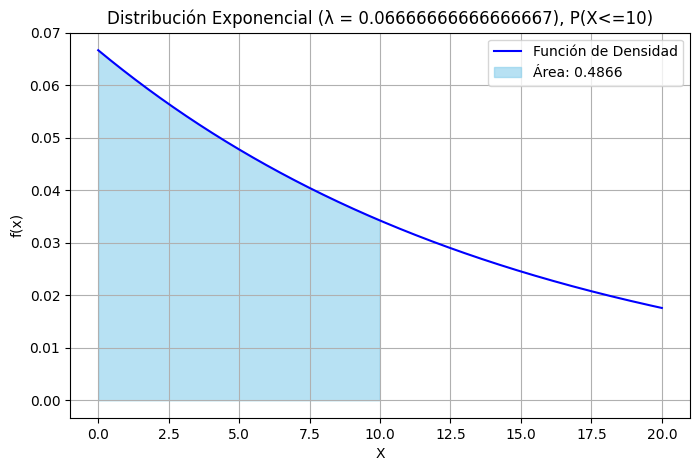

El valor del área sombreada para P(X<=10) es: 0.4866


In [9]:
# Parámetro lambda

lambda_param = 1/15  # taza de llegada de clientes

# Pregunta : P(X ≤ 10)
x = 10
prob1 = 1 - np.exp(-lambda_param * x)

# Mostrar resultados
print(f"P(X ≤ 10) = {prob1:.4f} ≈ {prob1*100:.4f}%")

# Llamar la función
f_prob_visual_exponencial(lambda_param, expresion="P(X<=10)") # Probabilidad de que x sea menor o o igual a 10


¿Cuál es la probabilidad de que el siguiente cliente llegue después de 20 minutos?
$$
F(x \ge 20)
$$

P(X ≥ 20) = 0.2636 ≈ 26.3597%


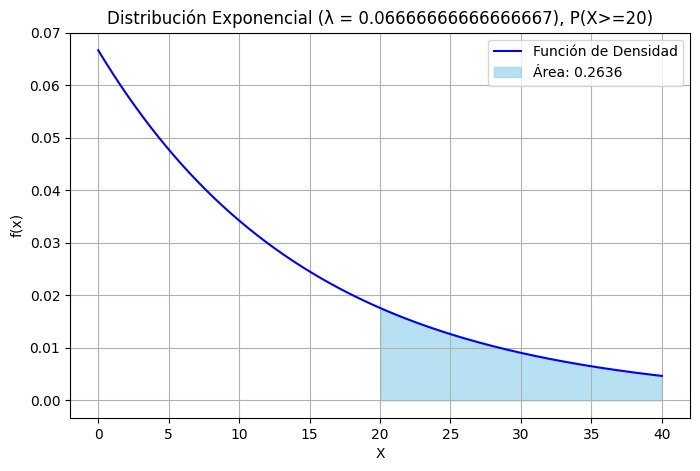

El valor del área sombreada para P(X>=20) es: 0.2636


In [10]:
# Parámetro lambda

lambda_param = 1/15  # taza de llegada de clientes

# Pregunta : P(X ≥ 20)
x = 20
prob1 = np.exp(-lambda_param * x)

# Mostrar resultados
print(f"P(X ≥ 20) = {prob1:.4f} ≈ {prob1*100:.4f}%")

# Llamar la función
f_prob_visual_exponencial(lambda_param, expresion="P(X>=20)") # Probabilidad de que x sea menor o o igual a 10


# Interpretación

# Interpretación

- ¿Cómo se generan números aleatorios de una distribución exponencial en Python? Con *np.random.exponential(scale=1/lambda, size=n)*, donde $scale = 1/\lambda$ es la media. También se puede con *stats.expon.rvs(scale=1/lambda, size=n)*. En el caso se generaron 10,000 valores.
- ¿Para qué se puede utilizar una distribución exponencial? Para modelar el tiempo hasta que ocurre un evento cuando los eventos pasan al azar con una tasa constante. Por ejemplo, el tiempo entre llegadas de clientes (banco, cajero, cafetería), la vida útil de un producto, el tiempo entre fallas de un sistema o el tiempo entre sismos.
- ¿Qué significa el valor esperado, la varianza y la desviación estándar de una distribución exponencial? El valor esperado $E(X) = \frac{1}{\lambda}$ es el tiempo promedio de espera hasta el siguiente evento. La varianza $\sigma^2 = \frac{1}{\lambda^2}$ y la desviación estándar $\sigma = \frac{1}{\lambda}$ dicen qué tanto varía ese tiempo; en la exponencial la desviación estándar es igual a la media. Por ejemplo, con $\lambda = 3$ llegadas por minuto el tiempo promedio es $0.3333$ minutos (20 segundos), y en la cafetería con $\lambda = 1/15$ el promedio es 15 minutos con desviación estándar de 15 minutos.
- ¿Cuál es la probabilidad de $P(X \le 0.5)$? La probabilidad de que el siguiente cliente llegue en menos de 30 segundos es $0.7769$, aproximadamente $77.69\%$.
- ¿Cuál es la probabilidad de $P(X > 1)$? La probabilidad de que el siguiente cliente tarde más de 1 minuto en llegar es $0.0498$, aproximadamente $4.98\%$.
- En la cafetería ($\lambda = 1/15$): la probabilidad de que el siguiente cliente llegue antes de 10 minutos es $P(X \le 10) = 0.4866$, o sea $48.66\%$, y la probabilidad de que llegue después de 20 minutos es $P(X \ge 20) = 0.2636$, o sea $26.36\%$.
- ¿Cómo se calculan probabilidades de una distribución exponencial? Con la función acumulada $F(x) = P(X \le x) = 1 - e^{-\lambda x}$; en Python con *stats.expon.cdf(x, scale=1/lambda)*. Para "más de x" se usa $P(X > x) = e^{-\lambda x}$, o sea $1 - F(x)$.
- ¿Qué les deja el caso? Me deja ver que la exponencial sirve para el tiempo de espera entre eventos y que se relaciona con Poisson: Poisson cuenta cuántos eventos hay en un tiempo y la exponencial mide cuánto tiempo pasa entre uno y otro. También que con solo el valor de $\lambda$ ya se puede calcular el promedio, la variación y las probabilidades.
